In [1]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('/content/WineQT.csv')

In [3]:
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,2
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,3
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595


In [4]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [5]:
df_enc

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,25,74,0,10,39,9,28,305,62,17,10,2,0
1,29,110,0,20,61,23,61,246,31,29,15,2,1
2,29,86,4,17,55,13,48,260,37,26,15,2,2
3,62,12,56,10,38,15,54,315,27,19,15,3,3
4,25,74,0,10,39,9,28,305,62,17,10,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,14,40,13,17,39,27,34,166,53,36,30,3,1138
1139,19,58,8,10,31,26,32,226,53,43,11,3,1139
1140,13,54,8,11,53,30,38,105,56,19,24,2,1140
1141,10,45,10,15,25,38,45,119,63,37,33,3,1141


In [7]:
x = df_enc[['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']]
y = df_enc['Id']

In [8]:
x

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,25,74,0,10,39,9,28,305,62,17,10,2
1,29,110,0,20,61,23,61,246,31,29,15,2
2,29,86,4,17,55,13,48,260,37,26,15,2
3,62,12,56,10,38,15,54,315,27,19,15,3
4,25,74,0,10,39,9,28,305,62,17,10,2
...,...,...,...,...,...,...,...,...,...,...,...,...
1138,14,40,13,17,39,27,34,166,53,36,30,3
1139,19,58,8,10,31,26,32,226,53,43,11,3
1140,13,54,8,11,53,30,38,105,56,19,24,2
1141,10,45,10,15,25,38,45,119,63,37,33,3


In [9]:
y

,Id
0,0
1,1
2,2
3,3
4,4
...,...
1138,1138
1139,1139
1140,1140
1141,1141


In [10]:
model = CategoricalNB()
model.fit(x, y)


CategoricalNB()

In [11]:
test = [25,74,0,10,39,9,28,305,62,17,10,2]

In [12]:
test

[25, 74, 0, 10, 39, 9, 28, 305, 62, 17, 10, 2]

In [15]:
test_samples = [test]
print("\n---prediction-----------------------------------")
for t in test_samples:
    row_df = pd.DataFrame([t], columns=x.columns)

    # Predict the Id label
    pred_encoded = model.predict(row_df)[0]
    pred_original = le['Id'].inverse_transform([pred_encoded])[0]
    prob = model.predict_proba(row_df)[0]

    # Decode the features back to their original values
    orig_features = {}
    for col in x.columns:
        orig_features[col] = le[col].inverse_transform([row_df[col].iloc[0]])[0]

    print("input features:")
    for col, val in orig_features.items():
        print(f"  {col}: {val}")
    print(f"output : Predicted Id = {pred_original} (encoded: {pred_encoded})")


---prediction-----------------------------------
input features:
  fixed acidity: 7.4
  volatile acidity: 0.7
  citric acid: 0.0
  residual sugar: 1.9
  chlorides: 0.076
  free sulfur dioxide: 11.0
  total sulfur dioxide: 34.0
  density: 0.9978
  pH: 3.51
  sulphates: 0.56
  alcohol: 9.4
  quality: 5
output : Predicted Id = 0 (encoded: 0)


In [16]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 89.06%


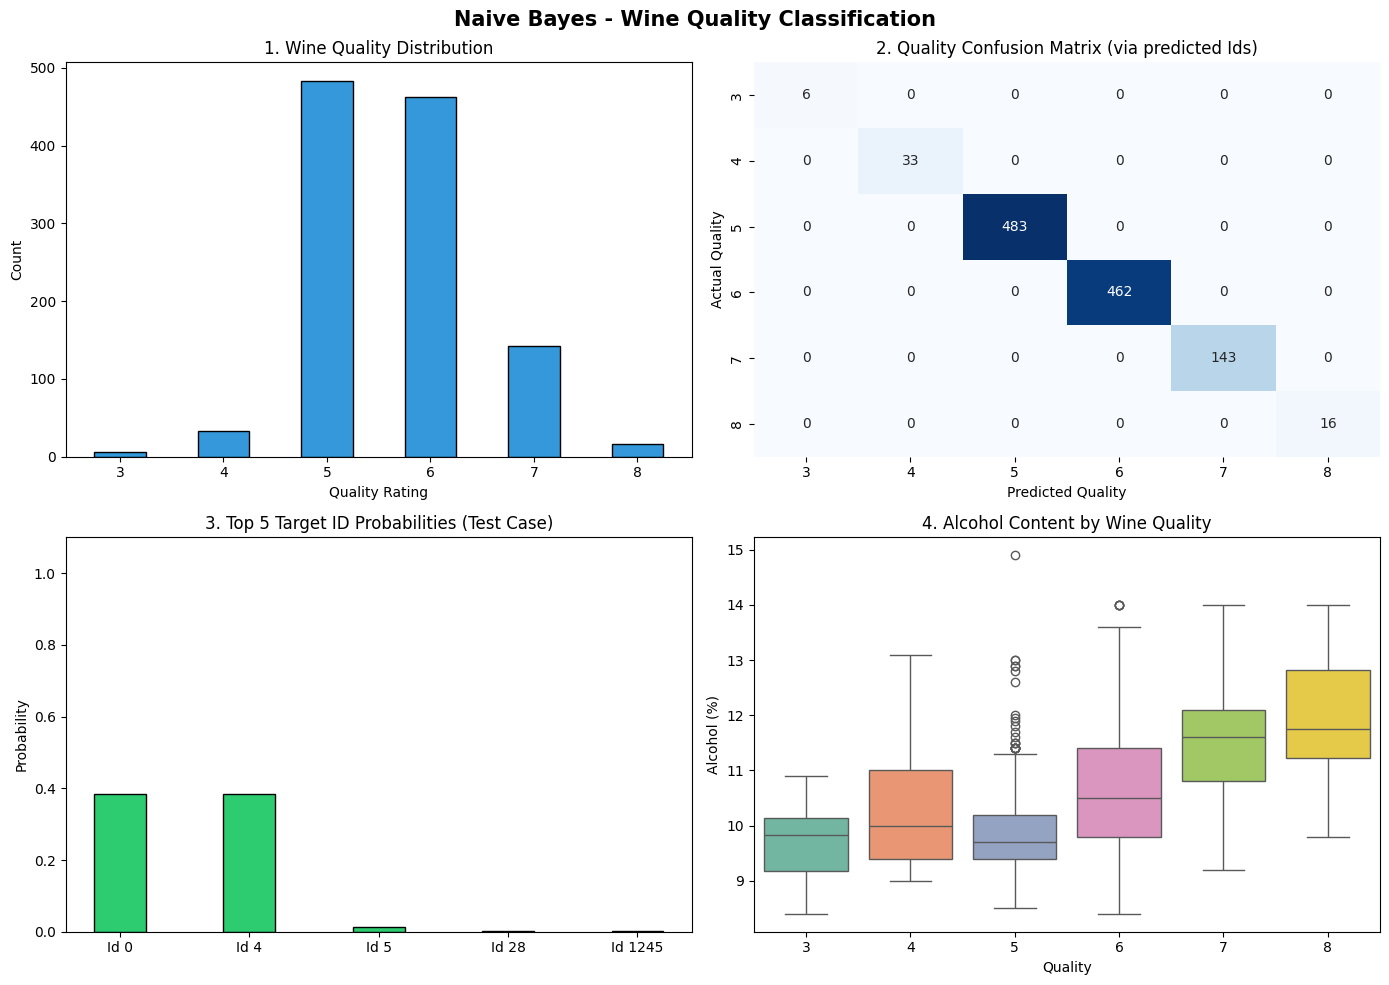

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Configure subplots for Wine dataset analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Naive Bayes - Wine Quality Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution (Wine Quality)
counts = df['quality'].value_counts().sort_index()
axes[0, 0].bar(counts.index.astype(str), counts.values, color='#3498db', edgecolor='black', width=0.5)
axes[0, 0].set_title("1. Wine Quality Distribution")
axes[0, 0].set_xlabel("Quality Rating")
axes[0, 0].set_ylabel("Count")

# 2. Predicted vs Actual Quality (since Id has 1143 classes, let's visualize quality prediction distribution)
# We'll map predicted Ids back to their training quality to see how well we're matching quality
pred_df = pd.DataFrame({'Actual Quality': df['quality'], 'Predicted Id': y_pred})
pred_df['Predicted Quality'] = pred_df['Predicted Id'].map(df['quality'])

cm = confusion_matrix(pred_df['Actual Quality'], pred_df['Predicted Quality'])
labels = sorted(pred_df['Actual Quality'].unique())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1], cbar=False,
            xticklabels=labels, yticklabels=labels)
axes[0, 1].set_title("2. Quality Confusion Matrix (via predicted Ids)")
axes[0, 1].set_xlabel("Predicted Quality")
axes[0, 1].set_ylabel("Actual Quality")

# 3. Top Prediction Probabilities for the Test Case
prob = model.predict_proba(test_df)[0]
top_indices = np.argsort(prob)[-5:][::-1]  # Get top 5 predicted Ids
top_probs = prob[top_indices]
top_classes = le['Id'].inverse_transform(top_indices)

axes[1, 0].bar(range(len(top_probs)), top_probs, color='#2ecc71', edgecolor='black', width=0.4)
axes[1, 0].set_title("3. Top 5 Target ID Probabilities (Test Case)")
axes[1, 0].set_xticks(range(len(top_probs)))
axes[1, 0].set_xticklabels([f"Id {c}" for c in top_classes])
axes[1, 0].set_ylabel("Probability")
axes[1, 0].set_ylim(0, 1.1)

# 4. Alcohol vs Quality distribution in dataset with resolved deprecation warning
sns.boxplot(data=df, x='quality', y='alcohol', ax=axes[1, 1], hue='quality', palette='Set2', legend=False)
axes[1, 1].set_title("4. Alcohol Content by Wine Quality")
axes[1, 1].set_xlabel("Quality")
axes[1, 1].set_ylabel("Alcohol (%)")

plt.tight_layout()
plt.show()